In [1]:
pip install pandas scikit-learn matplotlib

Dataset:
   Age  Income_k Student Credit_Rating Buys_Product
0   22        25     Yes          Fair           No
1   25        30     Yes          Fair           No
2   28        35      No          Fair           No
3   32        45      No          Good          Yes
4   35        50      No          Good          Yes

Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 3]]

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         2
         Yes       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


Decision Tree Rules:
|--- remainder__Income_k <= 39.50
|   |--- class: No
|--- remainder__Income_k >  39.50
|   |--- class: Yes



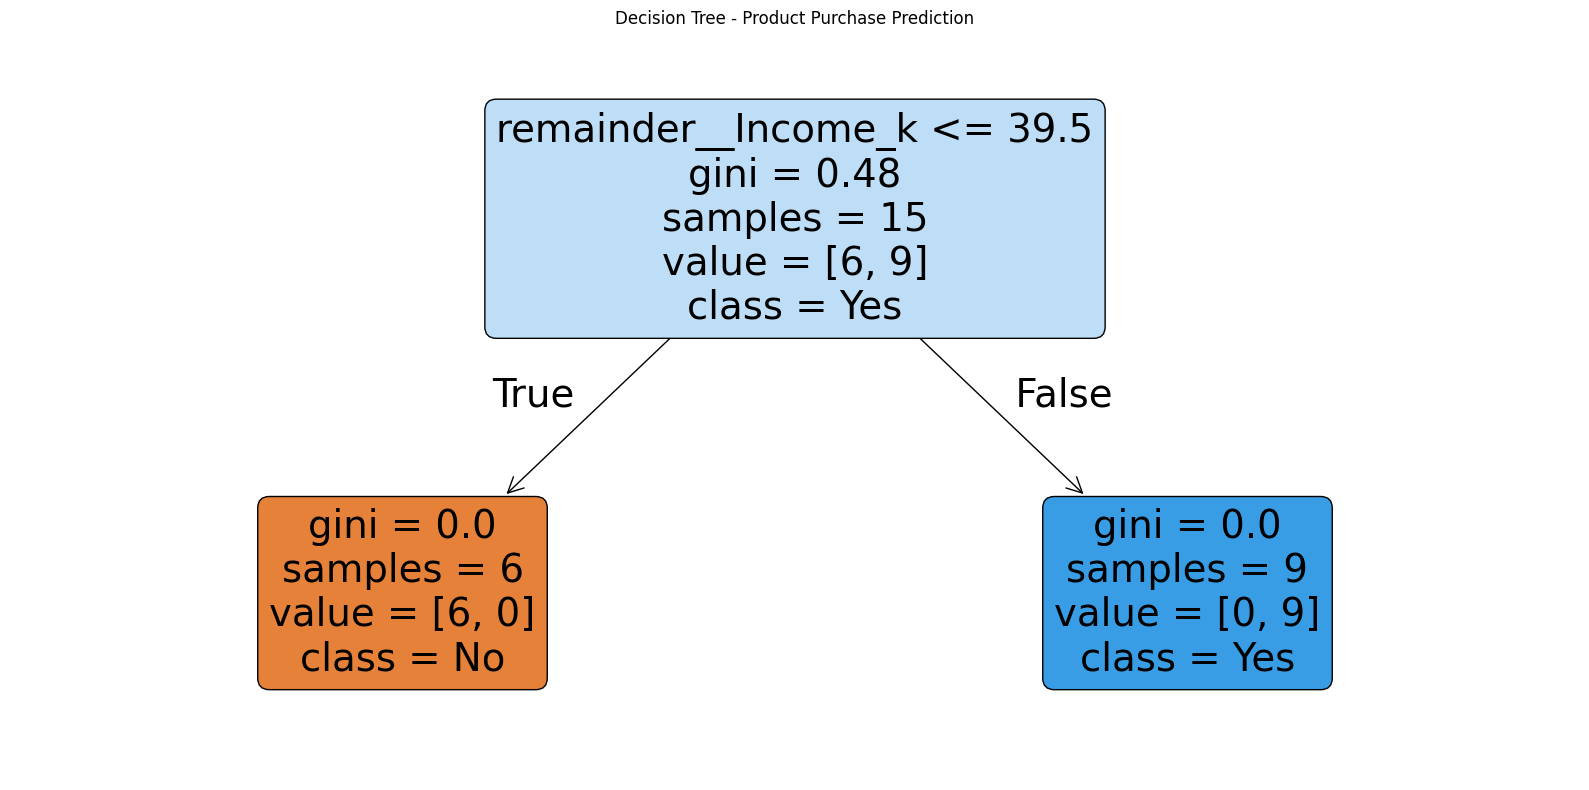


New Customer Prediction: Yes


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("decision_tree_practice_dataset.csv")

print("Dataset:")
print(df.head())

X = df.drop(columns=["Buys_Product"])
y = df["Buys_Product"]

numerical_features = ["Age", "Income_k"]
categorical_features = ["Student", "Credit_Rating"]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
], remainder="passthrough")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
tree = model.named_steps["classifier"]

print("\nDecision Tree Rules:")
print(export_text(tree, feature_names=list(feature_names)))

plt.figure(figsize=(16, 8))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_,
    filled=True,
    rounded=True
)
plt.title("Decision Tree - Product Purchase Prediction")
plt.tight_layout()
plt.show()

new_customer = pd.DataFrame([{
    "Age": 30,
    "Income_k": 40,
    "Student": "No",
    "Credit_Rating": "Good"
}])

prediction = model.predict(new_customer)[0]
print("\nNew Customer Prediction:", prediction)